# Comparing protein stability predictors on oncogenic KRAS mutations

## Data
ΔΔG values (kcal/mol) for seven oncogenic KRAS mutations, obtained from the DynaMut server. Positive values indicate stabilization and negative values indicate destabilization.

In [3]:
import pandas as pd

data = {
    "mutation": ["Q61L", "G12S", "G12R", "G12D", "G12A", "G12V", "G13D"],
    "DynaMut":  [-0.322, -0.279,  1.533,  1.562,  0.356,  0.818, -0.494],
    "ENCoM":    [-0.250,  0.382,  1.101,  0.629,  0.022,  0.460,  0.389],
    "mCSM":     [ 0.028, -0.583, -0.319, -0.096, -0.338, -0.356, -0.379],
    "SDM":      [ 1.470, -0.870, -0.310,  0.110,  0.440,  0.160, -3.500],
    "DUET":     [ 0.625, -0.535, -0.264,  0.217, -0.017, -0.100, -0.862],
}

df = pd.DataFrame(data)
df

,mutation,DynaMut,ENCoM,mCSM,SDM,DUET
0,Q61L,-0.322,-0.250,0.028,1.47,0.625
1,G12S,-0.279,0.382,-0.583,-0.87,-0.535
2,G12R,1.533,1.101,-0.319,-0.31,-0.264
3,G12D,1.562,0.629,-0.096,0.11,0.217
4,G12A,0.356,0.022,-0.338,0.44,-0.017
5,G12V,0.818,0.460,-0.356,0.16,-0.100
6,G13D,-0.494,0.389,-0.379,-3.50,-0.862


## Disagreement between predictors
For each mutation, the range is the difference between the highest and lowest predicted ΔΔG.

In [4]:
predictors = ["DynaMut", "ENCoM", "mCSM", "SDM", "DUET"]

df["range"] = df[predictors].max(axis=1) - df[predictors].min(axis=1)

df.sort_values("range", ascending=False)

,mutation,DynaMut,ENCoM,mCSM,SDM,DUET,range
6,G13D,-0.494,0.389,-0.379,-3.50,-0.862,3.889
2,G12R,1.533,1.101,-0.319,-0.31,-0.264,1.852
0,Q61L,-0.322,-0.250,0.028,1.47,0.625,1.792
3,G12D,1.562,0.629,-0.096,0.11,0.217,1.658
1,G12S,-0.279,0.382,-0.583,-0.87,-0.535,1.252
5,G12V,0.818,0.460,-0.356,0.16,-0.100,1.174
4,G12A,0.356,0.022,-0.338,0.44,-0.017,0.778


## Do the predictors agree on the direction?
For each mutation, count how many predictors call it stabilizing (ΔΔG > 0) and how many call it destabilizing (ΔΔG < 0).

In [5]:
df["n_stabilizing"] = (df[predictors] > 0).sum(axis=1)
df["n_destabilizing"] = (df[predictors] < 0).sum(axis=1)

df[["mutation", "n_stabilizing", "n_destabilizing", "range"]]

,mutation,n_stabilizing,n_destabilizing,range
0,Q61L,3,2,1.792
1,G12S,1,4,1.252
2,G12R,2,3,1.852
3,G12D,4,1,1.658
4,G12A,3,2,0.778
5,G12V,3,2,1.174
6,G13D,1,4,3.889


## Heatmap of predictions
Blue cells are predicted stabilizing, red cells destabilizing, and white is close to zero.

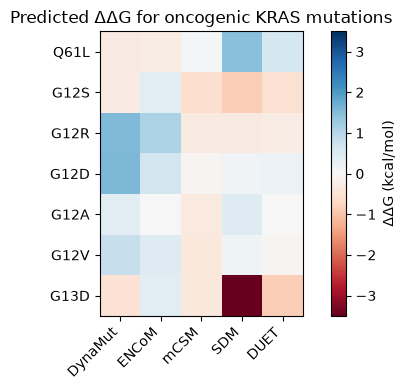

In [7]:
import matplotlib.pyplot as plt

values = df.set_index("mutation")[predictors]

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(values, cmap="RdBu", vmin=-3.5, vmax=3.5)

ax.set_xticks(range(len(predictors)))
ax.set_xticklabels(predictors, rotation=45, ha="right")
ax.set_yticks(range(len(values)))
ax.set_yticklabels(values.index)

fig.colorbar(im, label="ΔΔG (kcal/mol)")
ax.set_title("Predicted ΔΔG for oncogenic KRAS mutations")

plt.tight_layout()
plt.savefig("ddg_heatmap.png", dpi=300)
plt.show()

In [8]:
df[["mutation"] + predictors].to_csv("kras_ddg_predictions.csv", index=False)

## Summary
- None of the seven mutations received the same direction (stabilizing or destabilizing) from all five predictors. The highest agreement was for G12D (4 of 5).
- G13D showed the largest disagreement (range 3.889 kcal/mol), mainly because SDM predicted a strong destabilization (−3.5 kcal/mol).
- Most predicted values were small, so disagreement in sign for these mutations is not surprising and single-tool predictions should be interpreted with caution.

## Limitations
- Only seven mutations were analyzed.
- All predictions were obtained from the DynaMut server output, and they were not compared with experimental measurements.